In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [2]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [ ]:
df = pd.DataFrame(lista_alumnos, columns=['Nombre', 'Edad', 'Altura'])

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


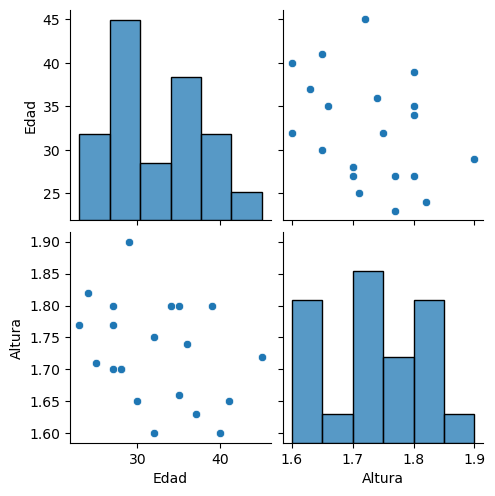

In [10]:
sns.pairplot(df);

<Axes: xlabel='Edad', ylabel='Altura'>

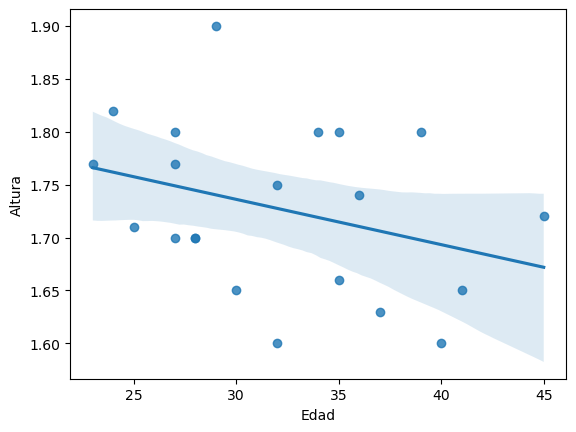

In [30]:
sns.regplot(df, x='Edad', y='Altura')

### Entrena un modelo de regresión lineal

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [11]:
X = df[['Edad']]
X

,Edad
0,24
1,25
2,35
3,37
4,29
5,27
6,28
7,32
8,36
9,45


In [12]:
y = df['Altura']
y

0     1.82
1     1.71
2     1.66
3     1.63
4     1.90
5     1.80
6     1.70
7     1.60
8     1.74
9     1.72
10    1.65
11    1.65
12    1.60
13    1.80
14    1.77
15    1.75
16    1.70
17    1.80
18    1.77
19    1.70
20    1.80
Name: Altura, dtype: float64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 4, random_state = 42)

In [19]:
lr = LinearRegression()

In [33]:
lr.fit(X_train, y_train)

LinearRegression()

In [28]:
lr.intercept_

1.8538095697472503

In [29]:
lr.coef_

array([-0.00415879])

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [21]:
from sklearn import metrics

In [23]:
lr.score(X_test, y_test)

-0.9556887365407647

In [24]:
predictions = lr.predict(X_test)

In [34]:
predictions

array([1.75399865, 1.71241077, 1.72072834, 1.74983986])

In [62]:
df_2 = df.copy()

In [63]:
df_2['Altura pred'] = lr.predict(df_2[['Edad']])
df_2['Error'] = df_2['Altura'] - df_2['Altura pred']
df_2['Error cuad'] = df_2['Error'] ** 2

In [64]:
df_2

,Nombre,Edad,Altura,Altura pred,Error,Error cuad
0,Leonardo S,24,1.82,1.753999,0.066001,0.004356
1,Piero T,25,1.71,1.749840,-0.039840,0.001587
2,Marta B,35,1.66,1.708252,-0.048252,0.002328
3,Silvia P,37,1.63,1.699934,-0.069934,0.004891
4,Faro Z,29,1.90,1.733205,0.166795,0.027821
5,Miguel N,27,1.80,1.741522,0.058478,0.003420
6,Alejandro M,28,1.70,1.737363,-0.037363,0.001396
7,Cristina M,32,1.60,1.720728,-0.120728,0.014575
8,Francisco P,36,1.74,1.704093,0.035907,0.001289
9,Jorge D,45,1.72,1.666664,0.053336,0.002845


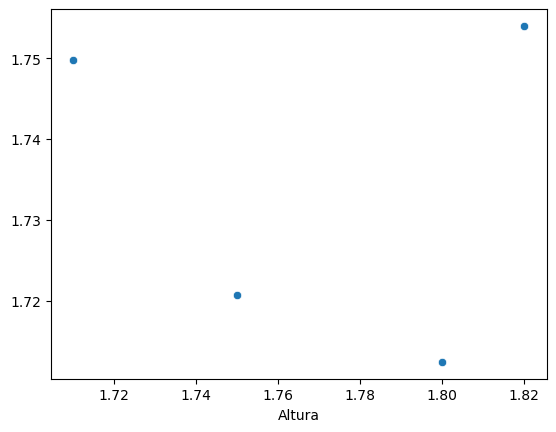

In [43]:
sns.scatterplot(x = y_test, y = predictions);

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


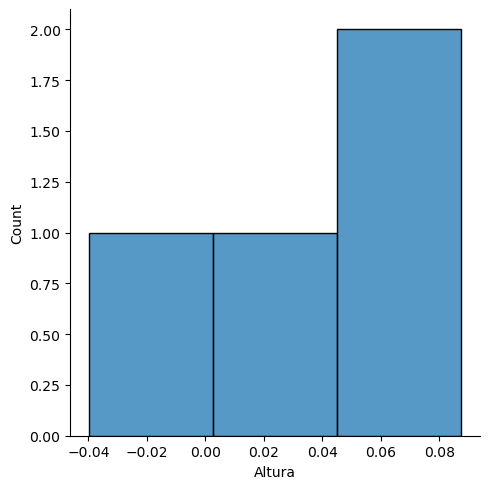

In [44]:
sns.displot((y_test - predictions));

In [45]:
import numpy as np

In [51]:
print('MAE:', metrics.mean_absolute_error(df_2['Altura'], df_2['Altura pred']))
print('MSE:', metrics.mean_squared_error(df_2['Altura'], df_2['Altura pred']))
# print('RMSE:', metrics.root_mean_squared_error(df_2['Altura'], df_2['Altura pred']))
print('RMSE:', np.sqrt(metrics.mean_squared_error(df_2['Altura'], df_2['Altura pred'])))
print('MAPE:', metrics.mean_absolute_percentage_error(y_true=df_2['Altura'], y_pred=df_2['Altura pred']))

MAE: 0.06345888114072566
MSE: 0.005346611421396251
RMSE: 0.07312052667614102
MAPE: 0.03663772184396239


In [65]:
lr.score(df_2[['Edad']], df_2[['Altura']])

0.10053573020685669

In [61]:
metrics.r2_score(df_2[['Altura']], df_2[['Altura pred']])

0.10053573020685669

In [47]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print('MAPE:', metrics.mean_absolute_percentage_error(y_true=y_test, y_pred=predictions))

MAE: 0.05567552575728357
MSE: 0.0036180241626004206
RMSE: 0.060150013820450786
MAPE: 0.031237497406006374
